# Final Project
## Predicting 30-Day Hospital Readmission in Diabetic Patients

Data Selection

For my project, I use the  Diabetes 130-US Hospitals for Years 1999–2008 dataset from the UC Irvine Machine Learning Repository (https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008)

The dataset comes from the Health Facts database (Cerner), which includes ten years of inpatient diabetic encounters at 130 US hospitals and integrated delivery networks (Strack et al., 2014). The target variable is readmitted, which has the values `<30`, `>30`, `NO`, and the binary target will specifically be 1 is readmitted is `<30` and 0 otherwise.

I chose this dataset because my capstone project will be on heart failure readmission prediction, so exploring a different chronic condition and its readmission factors may be helpful for my overall goal. This dataset has many clinical features across demographics and lab results, and the data seems to be large and overall well documented.

Specifically in terms of predictor variables, there's data on demographics (race, gender, age weight), Admission and discharge (admisson_type_id, admission_source_id, etc), the hospital stay length(time_in_hosiptal), diagnoses, lab results, and treatment summary, all of which provide a comprehensive view of the patient's inpatient care and can provide some predictive support for potential readmission risk.



Project Overview

My project problem is, at the time of discharge, predict whether a hospitalized diabetic patient will be readmitted to the hospital within 30 days, using demographics, admission and discharge information, prior-year utilization, laboratory indicators, diagnoses, and medication management.

The target variable is readmitted, suitable for binary in that if readmitted is < 30 then the value is 1, otherwise it is 0.

I use PR-AUC (Average Precision) as my evaluation metrics, because it is threshold-free and focused on the rare positive class, so it is more informative than ROC-AUC under imbalance (since the positive class is only about 11% of encounters).

This notebook has the following the following sections:
1. Data Input
2. Data Exploration
3. Inferential Statisitcs and Classification Models
4. Model evaluation
5. Pipeline enhancements

UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

## 1. Data Input and Validation

This section lets the user upload the dataset from their own computer, then profiles and validates it before any analysis runs. `load_data()` tries three sources in order: (1) a file the user uploads, (2) a `diabetic_data.csv` already in the working folder, and (3) a download from UCI. Only `?` is treated as missing: in the two lab-test columns the value `None` means "test not performed," which is meaningful, so it is kept as a real category. `validate()` raises a clear error if required columns are missing, the target is not binary, encounter IDs repeat, or there are fewer than 300 rows (the project minimum).

In [1]:
# Only needed for the fallback download from UCI (not needed if you upload the CSV)
!pip install -q ucimlrepo

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, ConfusionMatrixDisplay, f1_score,
                             precision_score, PrecisionRecallDisplay, recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- Settings: edit these to change how the pipeline behaves ----------------
RANDOM_STATE = 123          # random seed, so results are reproducible
TEST_SIZE = 0.20            # share of patients held out for testing
PRIMARY_METRIC = "PR-AUC"   # metric used to select the best model (set BEFORE looking at results)
TOP_K = 0.10                # alert budget: share of patients that care managers can follow up with
MISSING_THRESHOLD = 0.50    # columns with a larger share of missing values are dropped automatically
SVM_MAX_ROWS = 20_000       # above this many training rows a linear SVM replaces the (slow) RBF-SVM

# Input validation for the settings
VALID_METRICS = ["PR-AUC", "ROC-AUC", "F1", "Recall", "Precision", "Accuracy"]
if PRIMARY_METRIC not in VALID_METRICS:
    raise ValueError(f"PRIMARY_METRIC must be one of {VALID_METRICS}, got '{PRIMARY_METRIC}'")
if not (0 < TEST_SIZE < 1 and 0 < TOP_K < 1 and 0 < MISSING_THRESHOLD <= 1):
    raise ValueError("TEST_SIZE, TOP_K and MISSING_THRESHOLD must be between 0 and 1")
np.random.seed(RANDOM_STATE)

In [3]:
DATA_FILE = "diabetic_data.csv"
ID_COLUMNS = ["encounter_id", "patient_nbr"]
REQUIRED_COLUMNS = ID_COLUMNS + ["readmitted", "gender", "age", "discharge_disposition_id",
                                 "time_in_hospital", "number_inpatient"]


def load_data():
    """Load the data from (1) a user upload, (2) a local file, or (3) the UCI repository."""
    path = None
    try:                                              # Option 1: upload from the user's computer (Colab only)
        from google.colab import files
        print("Choose diabetic_data.csv from your computer (cancel to use the UCI download instead):")
        uploaded = files.upload()
        path = next(iter(uploaded), None)
    except ImportError:
        pass                                          # not running in Colab
    if path is None and os.path.exists(DATA_FILE):    # Option 2: file already in the working folder
        path = DATA_FILE

    if path is not None:
        if not path.lower().endswith(".csv"):
            raise ValueError(f"Expected a .csv file, got '{path}'")
        try:
            # only "?" is missing; "None" in the lab columns means "test not performed"
            data = pd.read_csv(path, na_values="?", keep_default_na=False, low_memory=False)
        except Exception as err:
            raise ValueError(f"Could not read '{path}': {err}")
        print(f"Loaded '{path}'")
    else:                                             # Option 3: download from UCI
        try:
            from ucimlrepo import fetch_ucirepo
        except ImportError:
            raise ImportError("Upload diabetic_data.csv, or run: pip install ucimlrepo")
        raw = fetch_ucirepo(id=296).data
        data = pd.concat([raw.ids, raw.features, raw.targets], axis=1).replace("?", np.nan)
        lab = ["max_glu_serum", "A1Cresult"]
        data[lab] = data[lab].fillna("None")          # NaN here means the test was not performed
        print("No file provided: downloaded the dataset from UCI")

    # Binary target: 1 = readmitted within 30 days, 0 = otherwise
    if "readmitted" in data.columns:
        data["target"] = (data["readmitted"] == "<30").astype(int)
    return data


def validate(data):
    """Stop early with a clear message if the data is not what the pipeline expects."""
    missing = [c for c in REQUIRED_COLUMNS + ["target"] if c not in data.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")
    if len(data) < 300:
        raise ValueError(f"Only {len(data)} rows; the project requires at least 300")
    if data["target"].nunique() != 2:
        raise ValueError("The target must contain both classes (0 and 1)")
    if not data["encounter_id"].is_unique:
        raise ValueError("encounter_id should be unique")
    if len(data.columns) - len(ID_COLUMNS) - 2 < 10:
        raise ValueError("The project requires at least 10 predictor columns")
    print(f"Validation passed: {len(data):,} rows, {len(data.columns) - 4} predictors, "
          f"readmission rate {data['target'].mean():.1%}")


def profile(data):
    """Automated profiling: size, duplicates, constant columns, and a per-column summary table."""
    table = pd.DataFrame({"dtype": data.dtypes.astype(str),
                          "n_unique": data.nunique(),
                          "pct_missing": data.isna().mean() * 100})
    print(f"Rows: {len(data):,} | Columns: {data.shape[1]} | Memory: {data.memory_usage().sum() / 1e6:.1f} MB")
    print(f"Duplicate rows: {data.duplicated().sum()} | Unique patients: {data['patient_nbr'].nunique():,}")
    print(f"Constant columns: {table.index[table['n_unique'] <= 1].tolist()}")
    print(f"Columns with missing values: {int((table['pct_missing'] > 0).sum())}")
    return table

In [4]:
df = load_data()
validate(df)

target_col = "readmitted"
feature_cols = [c for c in df.columns if c not in ID_COLUMNS + ["readmitted", "target"]]

profile_table = profile(df)
print("\nData upload and validation completed successfully.")
profile_table.sort_values("pct_missing", ascending=False).head(8)

Choose diabetic_data.csv from your computer (cancel to use the UCI download instead):


/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


No file provided: downloaded the dataset from UCI
Validation passed: 101,766 rows, 47 predictors, readmission rate 11.2%
Rows: 101,766 | Columns: 51 | Memory: 41.5 MB
Duplicate rows: 0 | Unique patients: 71,518
Constant columns: ['examide', 'citoglipton']
Columns with missing values: 7

Data upload and validation completed successfully.


,dtype,n_unique,pct_missing
weight,object,9,96.858
medical_specialty,object,72,49.082
payer_code,object,17,39.557
race,object,5,2.234
diag_3,object,789,1.398
diag_2,object,748,0.352
diag_1,object,716,0.021
admission_type_id,int64,8,0.000


The profile confirms that the data meets the project criteria: 101,766 encounters from 71,518 unique patients, 47 predictors, no duplicate rows, and an 11.2% 30-day readmission rate. Seven columns contain missing values, led by `weight` (96.9% missing), `medical_specialty` (49.1%) and `payer_code` (39.6%), while `race` (2.2%) and the three diagnosis columns (under 1.5%) are minor. Two columns (`examide`, `citoglipton`) never vary and carry no information. The gap between 71,518 patients and 101,766 encounters already shows that rows are not independent, which is handled during cleaning.

## 2. Data Processing and Exploration

In [5]:
print("Shape:", df.shape, "\n")
df.info()

Shape: (101766, 51) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 51 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-

In [6]:
num_cols = [c for c in ["time_in_hospital", "num_lab_procedures", "num_procedures",
                        "num_medications", "number_outpatient", "number_emergency",
                        "number_inpatient", "number_diagnoses"] if c in df.columns]

med_cols = [c for c in ["metformin","repaglinide","nateglinide","chlorpropamide","glimepiride",
                        "acetohexamide","glipizide","glyburide","tolbutamide","pioglitazone",
                        "rosiglitazone","acarbose","miglitol","troglitazone","tolazamide",
                        "examide","citoglipton","insulin","glyburide-metformin",
                        "glipizide-metformin","glimepiride-pioglitazone",
                        "metformin-rosiglitazone","metformin-pioglitazone"] if c in df.columns]

id_coded = [c for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"] if c in df.columns]

cat_cols = [c for c in feature_cols if c not in num_cols]
print(f"Numeric features     ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(cat_cols)}), of which")
print(f"   - integer-coded categories ({len(id_coded)}): {id_coded}")
print(f"   - medication columns       ({len(med_cols)})")
print(f"   - other (demographics, diagnoses, labs, etc.): {[c for c in cat_cols if c not in id_coded + med_cols]}")

Numeric features     (8): ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
Categorical features (39), of which
   - integer-coded categories (3): ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
   - medication columns       (23)
   - other (demographics, diagnoses, labs, etc.): ['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'change', 'diabetesMed']


In [7]:
print("Original 3-class distribution:")
print(pd.DataFrame({"count": df[target_col].value_counts(),
                    "share": df[target_col].value_counts(normalize=True)}), "\n")

print("Binary target distribution:")
tc = df["target"].value_counts().sort_index()
print(pd.DataFrame({"count": tc, "share": tc / tc.sum()}))
print(f"\nMajority-class baseline accuracy: {1 - df['target'].mean():.3%}")
print(f"Imbalance ratio (neg : pos) = {tc[0] / tc[1]:.1f} : 1")

Original 3-class distribution:
            count  share
readmitted              
NO          54864  0.539
>30         35545  0.349
<30         11357  0.112 

Binary target distribution:
        count  share
target              
0       90409  0.888
1       11357  0.112

Majority-class baseline accuracy: 88.840%
Imbalance ratio (neg : pos) = 8.0 : 1


The target is imbalanced: only 11.2% of encounters (11,357) were readmitted within 30 days, versus 88.8% that were not, a ratio of about 8 to 1. A model that always predicts "not readmitted" would be 88.8% accurate while identifying no one at risk, which is why accuracy is not used to choose a model and PR-AUC is the primary metric instead.

In [8]:
df[num_cols].describe().T.assign(skew=df[num_cols].skew(), n_missing=df[num_cols].isna().sum())

,count,mean,std,min,25%,50%,75%,max,skew,n_missing
time_in_hospital,"101,766.000",4.396,2.985,1.000,2.000,4.000,6.000,14.000,1.134,0
num_lab_procedures,"101,766.000",43.096,19.674,1.000,31.000,44.000,57.000,132.000,-0.237,0
num_procedures,"101,766.000",1.340,1.706,0.000,0.000,1.000,2.000,6.000,1.316,0
num_medications,"101,766.000",16.022,8.128,1.000,10.000,15.000,20.000,81.000,1.327,0
number_outpatient,"101,766.000",0.369,1.267,0.000,0.000,0.000,0.000,42.000,8.833,0
number_emergency,"101,766.000",0.198,0.930,0.000,0.000,0.000,0.000,76.000,22.856,0
number_inpatient,"101,766.000",0.636,1.263,0.000,0.000,0.000,1.000,21.000,3.614,0
number_diagnoses,"101,766.000",7.423,1.934,1.000,6.000,8.000,9.000,16.000,-0.877,0


In [9]:
cat_summary = pd.DataFrame({
    "n_unique": df[cat_cols].nunique(dropna=True),
    "n_missing": df[cat_cols].isna().sum(),
    "pct_missing": df[cat_cols].isna().mean() * 100,
    "most_common": df[cat_cols].mode().iloc[0],
    "most_common_pct": [df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols],
})
cat_summary.sort_values("pct_missing", ascending=False)

,n_unique,n_missing,pct_missing,most_common,most_common_pct
weight,9,98569,96.858,[75-100),41.789
medical_specialty,72,49949,49.082,InternalMedicine,28.244
payer_code,17,40256,39.557,MC,52.738
race,5,2273,2.234,Caucasian,76.487
diag_3,789,1423,1.398,250,11.516
diag_2,748,358,0.352,276,6.658
diag_1,716,21,0.021,428,6.744
admission_source_id,17,0,0.000,7,56.496
discharge_disposition_id,26,0,0.000,1,59.189
admission_type_id,8,0,0.000,1,53.053


In [10]:
for c in ["age", "gender", "race", "change", "diabetesMed", "A1Cresult", "max_glu_serum"]:
    if c in df.columns:
        print(f"\n--- 30-day readmission rate by {c} ---")
        print(df.groupby(c, dropna=False)["target"].agg(rate="mean", n="count").sort_index())


--- 30-day readmission rate by age ---
          rate      n
age                  
[0-10)   0.019    161
[10-20)  0.058    691
[20-30)  0.142   1657
[30-40)  0.112   3775
[40-50)  0.106   9685
[50-60)  0.097  17256
[60-70)  0.111  22483
[70-80)  0.118  26068
[80-90)  0.121  17197
[90-100) 0.111   2793

--- 30-day readmission rate by gender ---
                 rate      n
gender                      
Female          0.112  54708
Male            0.111  47055
Unknown/Invalid 0.000      3

--- 30-day readmission rate by race ---
                 rate      n
race                        
AfricanAmerican 0.112  19210
Asian           0.101    641
Caucasian       0.113  76099
Hispanic        0.104   2037
Other           0.096   1506
NaN             0.083   2273

--- 30-day readmission rate by change ---
        rate      n
change             
Ch     0.118  47011
No     0.106  54755

--- 30-day readmission rate by diabetesMed ---
             rate      n
diabetesMed             
No          0.

Most numeric features are right-skewed. The prior-visit counts are the most extreme (skew of 22.9 for `number_emergency`, 8.8 for `number_outpatient`, 3.6 for `number_inpatient`) because most patients had no visits in the prior year and a few had dozens, while lab procedures and number of diagnoses are roughly symmetric. Readmission rates differ only modestly across groups: they are nearly identical by gender (11.2% vs 11.1%) and range from 9.6% to 11.3% across the named race groups, are slightly higher when a diabetes medication was prescribed (11.6% vs 9.6%) or changed (11.8% vs 10.6%), and are highest when the peak glucose result exceeded 300 (14.3%). Age shows low rates in children (1.9% and 5.8% under age 20) and little pattern from age 30 onward (9.7% to 12.1%). The lab-test columns `A1Cresult` and `max_glu_serum` are "None" for 83% and 95% of encounters, meaning the test was not performed.

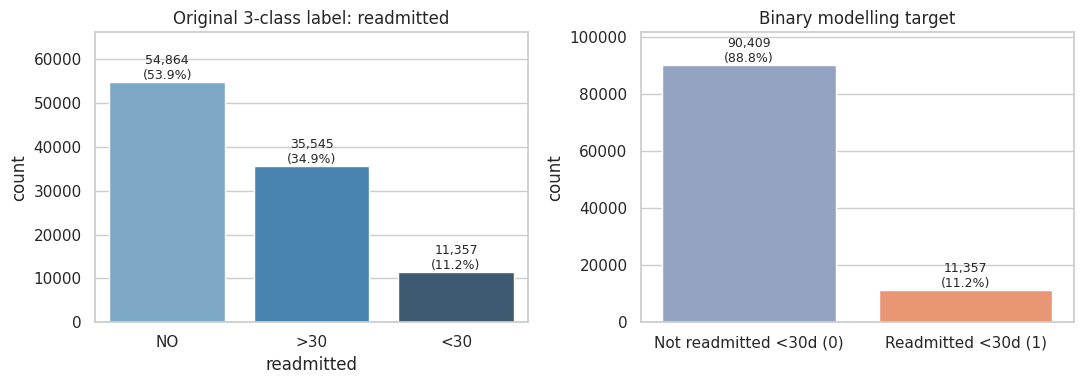

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

order3 = ["NO", ">30", "<30"]
sns.countplot(data=df, x=target_col, order=order3, palette="Blues_d", ax=axes[0])
axes[0].set_title("Original 3-class label: readmitted")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():,.0f}\n({p.get_height()/len(df):.1%})",
                     (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, len(df) * 0.65)

sns.countplot(data=df, x="target", palette=["#8da0cb", "#fc8d62"], ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Not readmitted <30d (0)", "Readmitted <30d (1)"])
axes[1].set_title("Binary modelling target")
axes[1].set_xlabel("")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():,.0f}\n({p.get_height()/len(df):.1%})",
                     (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, len(df) * 1.0)
plt.tight_layout(); plt.show()

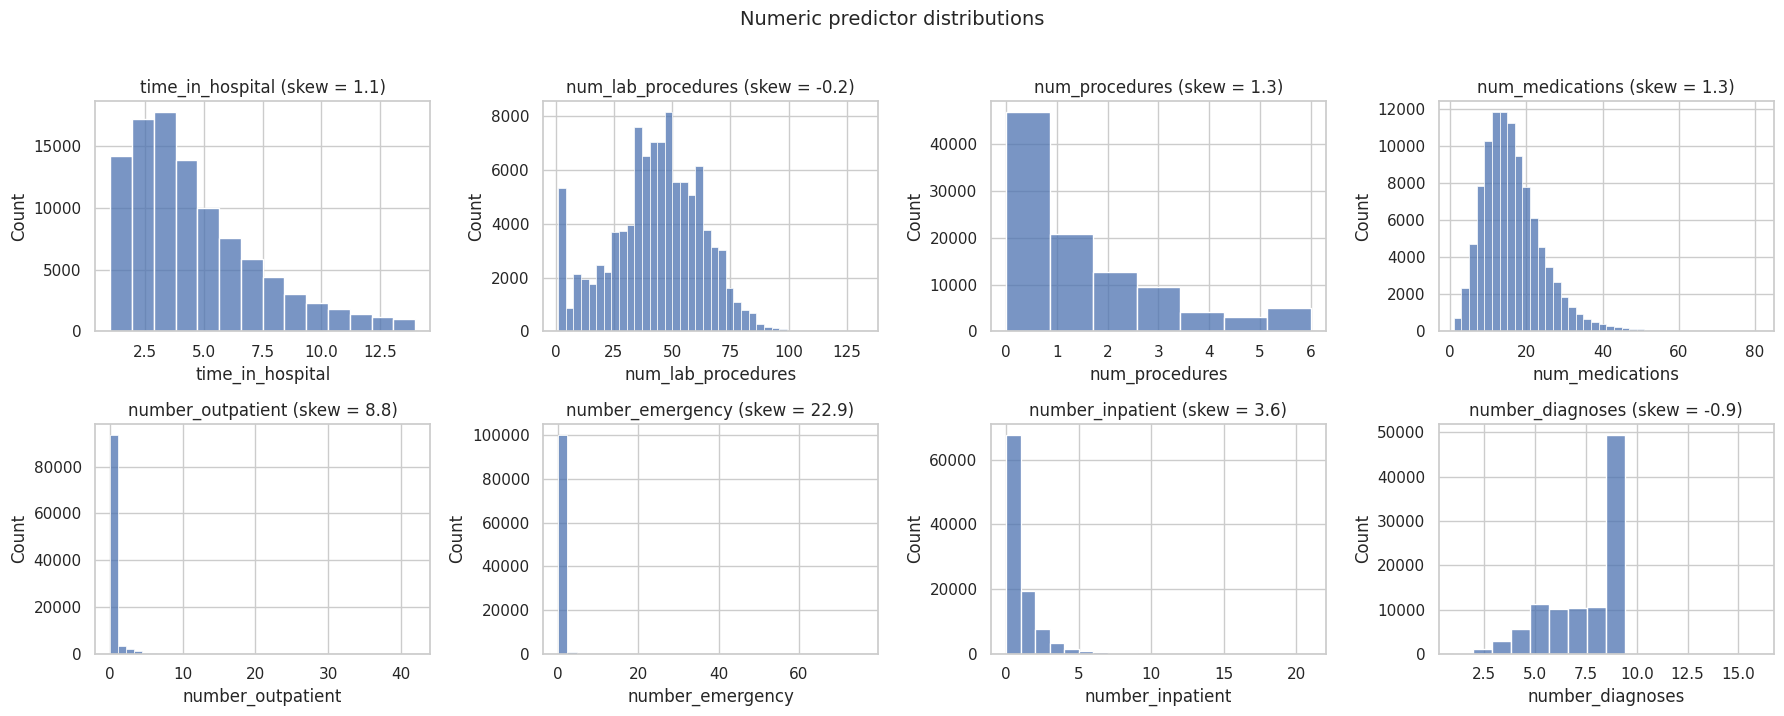

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=min(40, int(df[c].nunique())), ax=ax, color="#4c72b0")
    ax.set_title(f"{c} (skew = {df[c].skew():.1f})")
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.suptitle("Numeric predictor distributions", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

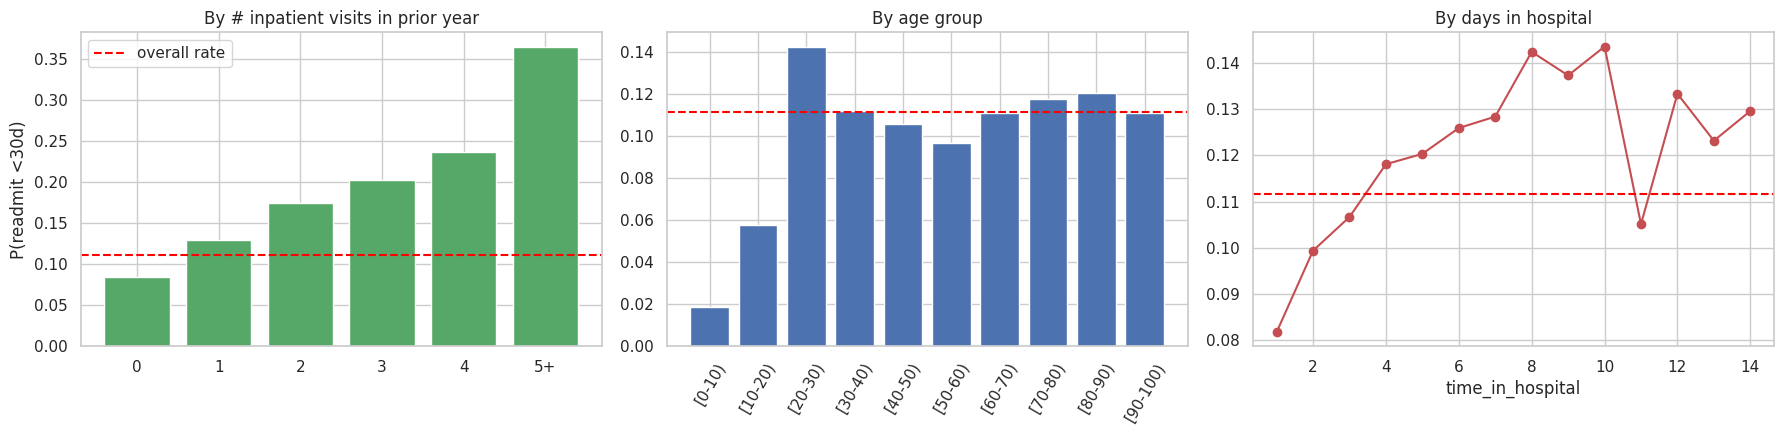

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

tmp = df.assign(prior_inpatient=df["number_inpatient"].clip(upper=5))
r = tmp.groupby("prior_inpatient")["target"].agg(["mean", "count"])
axes[0].bar(r.index.astype(str).str.replace("5", "5+"), r["mean"], color="#55a868")
axes[0].axhline(df["target"].mean(), color="red", ls="--", label="overall rate")
axes[0].set_title("By # inpatient visits in prior year"); axes[0].set_ylabel("P(readmit <30d)"); axes[0].legend()

r = df.groupby("age")["target"].mean()
axes[1].bar(r.index.astype(str), r.values, color="#4c72b0")
axes[1].axhline(df["target"].mean(), color="red", ls="--")
axes[1].set_title("By age group"); axes[1].tick_params(axis="x", rotation=60)

r = df.groupby("time_in_hospital")["target"].mean()
axes[2].plot(r.index, r.values, marker="o", color="#c44e52")
axes[2].axhline(df["target"].mean(), color="red", ls="--")
axes[2].set_title("By days in hospital"); axes[2].set_xlabel("time_in_hospital")
plt.tight_layout(); plt.show()

The plots show that prior utilization is the clearest signal: readmission rises steadily with the number of inpatient visits in the previous year, from 8.4% for patients with none to 36.4% for patients with five or more. Longer stays are also associated with somewhat higher risk (8.2% after a 1-day stay versus roughly 11-14% after 6 or more days), while age shows low rates only in children and a flat pattern in adults. The histograms confirm that the visit and medication counts pile up near zero with long right tails, which is why tree-based models, which are insensitive to skew, are included alongside the linear ones. The first figure repeats the class imbalance for both the original three-class label and the binary target.

In [14]:
miss = pd.DataFrame({"n_missing": df[feature_cols].isna().sum()})
miss["pct_missing"] = miss["n_missing"] / len(df) * 100
print(miss)

                          n_missing  pct_missing
race                           2273        2.234
gender                            0        0.000
age                               0        0.000
weight                        98569       96.858
admission_type_id                 0        0.000
discharge_disposition_id          0        0.000
admission_source_id               0        0.000
time_in_hospital                  0        0.000
payer_code                    40256       39.557
medical_specialty             49949       49.082
num_lab_procedures                0        0.000
num_procedures                    0        0.000
num_medications                   0        0.000
number_outpatient                 0        0.000
number_emergency                  0        0.000
number_inpatient                  0        0.000
diag_1                           21        0.021
diag_2                          358        0.352
diag_3                         1423        1.398
number_diagnoses    

In [15]:
# Improper codings
print("gender values:\n", df["gender"].value_counts(dropna=False), "\n")

if "discharge_disposition_id" in df.columns:
    # IDs 11 = Expired, 13/14 = Hospice, 19/20/21 = Expired variants (per UCI ID mapping)
    dead_hospice = [11, 13, 14, 19, 20, 21]
    d = pd.to_numeric(df["discharge_disposition_id"], errors="coerce")
    n_dead = d.isin(dead_hospice).sum()
    print(f"Encounters ending in death or hospice (cannot be readmitted): {n_dead:,} ({n_dead/len(df):.2%})")
    print("   readmit-<30 rate among them:", round(df.loc[d.isin(dead_hospice), 'target'].mean(), 4))

print("\nInteger-coded columns that are really categories:")
for c in id_coded:
    print(f"   {c}: {df[c].nunique()} distinct codes")

print("\nAge stored as text bins:", sorted(df["age"].dropna().unique())[:4], "...")
print("diag_1 examples (ICD-9; some start with 'V' or 'E'):", df["diag_1"].dropna().sample(6, random_state=1).tolist())
print("diag_1 distinct codes:", df["diag_1"].nunique(), "| diag_2:", df["diag_2"].nunique(), "| diag_3:", df["diag_3"].nunique())

gender values:
 gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64 

Encounters ending in death or hospice (cannot be readmitted): 2,423 (2.38%)
   readmit-<30 rate among them: 0.0177

Integer-coded columns that are really categories:
   admission_type_id: 8 distinct codes
   discharge_disposition_id: 26 distinct codes
   admission_source_id: 17 distinct codes

Age stored as text bins: ['[0-10)', '[10-20)', '[20-30)', '[30-40)'] ...
diag_1 examples (ICD-9; some start with 'V' or 'E'): ['250.6', '996', '440', '250.41', '486', '578']
diag_1 distinct codes: 716 | diag_2: 748 | diag_3: 789


The checks reveal three kinds of problems. First, missing values are concentrated in `weight` (96.9%, effectively unusable), `medical_specialty` (49.1%) and `payer_code` (39.6%), while the other columns are under 2.3%. Second, some codings are improper rather than missing: 3 encounters have gender `Unknown/Invalid`, the lab columns use "None" for "not performed," and `admission_type_id`, `discharge_disposition_id` and `admission_source_id` are integer codes that are really categories. Third, 2,423 encounters (2.4%) ended in death or hospice discharge and had a 30-day readmission rate of only 1.8%, so they cannot be treated like ordinary discharges. The plan below addresses each of these issues.

Data Quality Assessment

Several variables like weight, payer_code, medical_speciality, and race have missing values. Since weight is almost entirely missing, i'll probably drop the weight column. The other ones have a missing shares, but I'll create an Unknown category rather than dropping rows because they aren't as depleted.

Patients who passed away or went to hopsice will also be excluded because they can't be readmitted.

Several patients are repeated, so I'll keep one encounter per patient_nbr.


For integer-coded categories (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`), I plan to convert them to categorical, and merge rare codes and codes that mean the same thing. I am also planning on mapping high-cardinality ICD-9 codes to broad diagnostic groups (circulatory, respiratory, diabetes, digestive, injury, musculoskeletal, genitourinary, neoplasms, other).

To handle the class imbalance, I will use class weights and stratified splits when selecting parts of the data for training and validation.

Some challenges with this dataset include the class imbalance, which reduces the meaning of a simple accuracy value since you would score about 89% by predicting not radmitted for everyone, and the large number of missing values that may be informative based on the feature. Also, only readmission to the same system within 30 days is observed, so readmissions elsewhere are not available.

`clean()` applies the plan in one reusable function: it removes invalid or impossible encounters, keeps one encounter per patient so rows are independent, drops columns whose share of missing values exceeds `MISSING_THRESHOLD` (decided from the data rather than hard-coded) and constant columns, labels remaining missing categories `Unknown`, and builds new features (diagnosis groups, age midpoint, total prior visits, and counts of medications prescribed and changed).

In [16]:
def diag_group(code):
    """Map an ICD-9 diagnosis code to a broad diagnosis group."""
    if pd.isna(code) or str(code).startswith(("V", "E")):
        return "Other"
    c = float(code)
    if int(c) == 250:                      return "Diabetes"
    if 390 <= c < 460 or int(c) == 785:    return "Circulatory"
    if 460 <= c < 520 or int(c) == 786:    return "Respiratory"
    if 520 <= c < 580 or int(c) == 787:    return "Digestive"
    if 580 <= c < 630 or int(c) == 788:    return "Genitourinary"
    if 710 <= c < 740:                     return "Musculoskeletal"
    if 800 <= c < 1000:                    return "Injury"
    if 140 <= c < 240:                     return "Neoplasms"
    return "Other"


def clean(data):
    """Clean the data and engineer features; returns a modelling-ready DataFrame."""
    d = data[data["gender"] != "Unknown/Invalid"]                              # invalid gender code (a few rows)
    n_valid = len(d)
    d = d[~d["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]        # died or hospice: cannot be readmitted
    n_alive = len(d)
    d = d.sort_values("encounter_id").drop_duplicates("patient_nbr")            # keep each patient's first encounter
    print(f"Removed {len(data) - n_valid} invalid-gender, {n_valid - n_alive:,} died/hospice and "
          f"{n_alive - len(d):,} repeat encounters")

    # Data-driven column removal: too many missing values, IDs, the 3-class label, constant columns
    too_missing = d.columns[d.isna().mean() > MISSING_THRESHOLD].tolist()
    d = d.drop(columns=too_missing + ID_COLUMNS + ["readmitted"])
    constant = d.columns[d.nunique() <= 1].tolist()
    d = d.drop(columns=constant).copy()
    print(f"Dropped for >{MISSING_THRESHOLD:.0%} missing: {too_missing} | constant: {constant}")

    # Feature engineering
    meds = [c for c in d.columns if c in med_cols]                              # medication columns still present
    d["age"] = d["age"].str.extract(r"\[(\d+)")[0].astype(int) + 5              # age bin -> midpoint
    for c in ["diag_1", "diag_2", "diag_3"]:
        d[c] = d[c].map(diag_group)                                             # ICD-9 code -> broad group
    d["n_meds_prescribed"] = (d[meds] != "No").sum(axis=1)                      # medications prescribed
    d["n_meds_changed"] = d[meds].isin(["Up", "Down"]).sum(axis=1)              # dose increased or decreased
    d["total_prior_visits"] = d[["number_outpatient", "number_emergency", "number_inpatient"]].sum(axis=1)

    # Integer-coded categories -> text; remaining missing categories -> "Unknown"
    for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
        d[c] = d[c].astype(str)
    cat = d.select_dtypes(exclude="number").columns
    d[cat] = d[cat].fillna("Unknown")

    if d.isna().sum().sum() != 0:                                               # final safety check
        raise ValueError("Missing values remain after cleaning")
    return d


clean_df = clean(df)
print(f"Rows: {len(df):,} -> {len(clean_df):,} | predictors: {clean_df.shape[1] - 1} | "
      f"readmission rate: {clean_df['target'].mean():.1%}")
clean_df.describe().T

Removed 3 invalid-gender, 2,423 died/hospice and 29,353 repeat encounters
Dropped for >50% missing: ['weight'] | constant: ['examide', 'citoglipton', 'glimepiride-pioglitazone']
Rows: 101,766 -> 69,987 | predictors: 46 | readmission rate: 9.0%


,count,mean,std,min,25%,50%,75%,max
age,"69,987.000",65.443,15.974,5.000,55.000,65.000,75.000,95.000
time_in_hospital,"69,987.000",4.273,2.934,1.000,2.000,3.000,6.000,14.000
num_lab_procedures,"69,987.000",42.876,19.894,1.000,31.000,44.000,57.000,132.000
num_procedures,"69,987.000",1.425,1.757,0.000,0.000,1.000,2.000,6.000
num_medications,"69,987.000",15.665,8.287,1.000,10.000,14.000,20.000,81.000
number_outpatient,"69,987.000",0.280,1.064,0.000,0.000,0.000,0.000,42.000
number_emergency,"69,987.000",0.104,0.512,0.000,0.000,0.000,0.000,42.000
number_inpatient,"69,987.000",0.176,0.602,0.000,0.000,0.000,0.000,12.000
number_diagnoses,"69,987.000",7.224,2.001,1.000,6.000,8.000,9.000,16.000
target,"69,987.000",0.090,0.286,0.000,0.000,0.000,0.000,1.000


Cleaning reduced the data from 101,766 encounters to 69,987 patients by removing 3 invalid-gender rows, 2,423 died/hospice encounters and 29,353 repeat encounters. The function automatically dropped `weight` (the only column above the 50% missing threshold) and three constant columns, and added three engineered features, leaving 46 predictors. The readmission rate in the cleaned cohort is 9.0% (versus 11.2% before) because the repeat encounters that were removed were readmitted far more often than first encounters, so the no-skill PR-AUC baseline is now 0.09. Prior-visit counts also fall (mean `number_inpatient` drops from 0.64 to 0.18), a trade-off of keeping first encounters that is discussed in the limitations.

## 3. Analytical Pipeline

**Question:** do patients readmitted within 30 days differ from other patients? Two families of tests are used. For numeric features, the null hypothesis is that the mean is equal in both groups (Welch's *t*-test, with Mann-Whitney U as a robustness check because the counts are skewed). For categorical features, the null hypothesis is that the feature is independent of readmission (chi-square test of independence). Because the cleaned data has one encounter per patient, the independence assumption of these tests is reasonable.

**Formulas used.** Welch's *t*-statistic compares the mean of a feature in the readmitted group (1) and the not-readmitted group (0) without assuming equal variances:

$$t = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{\dfrac{s_1^2}{n_1} + \dfrac{s_0^2}{n_0}}}$$

Because $n$ is very large, even trivial differences give tiny p-values, so each test is paired with an effect size. For numeric features it is Cohen's $d$, the difference in means measured in standard deviations (small $\approx 0.2$, medium $\approx 0.5$, large $\approx 0.8$):

$$d = \frac{\bar{x}_1 - \bar{x}_0}{s_p}, \qquad s_p = \sqrt{\frac{s_1^2 + s_0^2}{2}}$$

For categorical features, the chi-square statistic compares observed counts $O_{ij}$ in a contingency table with the counts $E_{ij} = R_i C_j / N$ expected if the feature and readmission were independent, and Cramér's $V$ rescales it to a 0-1 effect size ($k$ is the smaller of the number of rows and columns):

$$\chi^2 = \sum_{i,j} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}, \qquad V = \sqrt{\frac{\chi^2}{N\,(k-1)}}$$

These formulas tie directly to the code below: the p-values answer "is there any difference?", while $d$ and $V$ answer "is the difference large enough to matter clinically and useful for prediction?"

In [17]:
# Numeric features: Welch t-test, Cohen's d, Mann-Whitney U
rows = []
for c in clean_df.select_dtypes("number").columns.drop("target"):
    g1 = clean_df.loc[clean_df["target"] == 1, c]
    g0 = clean_df.loc[clean_df["target"] == 0, c]
    sd = np.sqrt((g1.var() + g0.var()) / 2)
    rows.append({"feature": c,
                 "mean_readmitted": g1.mean(),
                 "mean_not_readmitted": g0.mean(),
                 "cohens_d": (g1.mean() - g0.mean()) / sd,
                 "welch_p": f"{stats.ttest_ind(g1, g0, equal_var=False).pvalue:.1e}",
                 "mannwhitney_p": f"{stats.mannwhitneyu(g1, g0).pvalue:.1e}"})
pd.DataFrame(rows).set_index("feature").sort_values("cohens_d", key=abs, ascending=False)

,mean_readmitted,mean_not_readmitted,cohens_d,welch_p,mannwhitney_p
feature,,,,,
number_inpatient,0.368,0.157,0.266,6.5e-62,7.6e-111
time_in_hospital,4.795,4.222,0.192,2.3e-45,4.0e-56
total_prior_visits,0.827,0.533,0.189,1.1e-39,1.9e-66
age,67.837,65.206,0.169,7.2e-39,1.5e-37
number_diagnoses,7.515,7.196,0.165,4.7e-38,2.9e-30
num_medications,16.620,15.571,0.126,1.8e-21,2.6e-29
num_lab_procedures,44.906,42.676,0.114,4.1e-18,1.0e-17
number_emergency,0.150,0.099,0.092,4.6e-11,1.3e-15
n_meds_changed,0.296,0.259,0.076,1.4e-08,1.2e-09


In [18]:
# Categorical features: chi-square test of independence with Cramer's V
for c in ["change", "diabetesMed", "A1Cresult", "gender"]:
    table = pd.crosstab(clean_df[c], clean_df["target"])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    print(f"{c:12s} chi2({dof}) = {chi2:7.1f}   p = {p:.1e}   Cramer's V = {v:.3f}")

change       chi2(1) =    14.7   p = 1.3e-04   Cramer's V = 0.014
diabetesMed  chi2(1) =    53.6   p = 2.5e-13   Cramer's V = 0.028
A1Cresult    chi2(3) =     7.4   p = 6.1e-02   Cramer's V = 0.010
gender       chi2(1) =     0.3   p = 5.9e-01   Cramer's V = 0.002


Most features differ significantly between the groups, but every effect is small. Among numeric features the largest is `number_inpatient` (Cohen's d = 0.27), followed by `time_in_hospital` (0.19), `total_prior_visits` (0.19), `age` (0.17) and `number_diagnoses` (0.17), while `num_procedures` shows no difference (d near 0, p = 0.94). Welch's t-test and Mann-Whitney U lead to the same conclusion for every feature at the 0.05 level, so the skewed counts do not change the result. Among categorical features, `diabetesMed` (V = 0.028) and `change` (V = 0.014) are associated with readmission but only weakly, whereas `A1Cresult` (p = 0.061) and `gender` (p = 0.59) are not significant. With 16 tests, a Bonferroni-adjusted threshold would be about 0.003, which `number_outpatient` (Welch p = 0.02) would no longer meet. With about 70,000 patients, significance is easy to reach, so the effect sizes matter more: no single variable separates the groups well, which anticipates the modest model performance below.

Five classifiers are trained: Logistic Regression (a simple, interpretable baseline), Decision Tree (rule-based and easy to explain), Random Forest and Gradient Boosting (ensembles that capture non-linear effects and interactions), and a Support Vector Machine. The data is split once into stratified training (80%) and test (20%) sets, so both keep the same readmission rate. All preprocessing (scaling numeric features, one-hot encoding categorical ones) sits inside each `Pipeline`, so it is learned from the training data only and cannot leak information from the test set. Two pieces of conditional logic adapt the pipeline to the data: class weights are used only if the positive class is rare, and a linear SVM replaces the RBF-SVM when the training set is too large for the RBF kernel to run in reasonable time (change `SVM_MAX_ROWS` to override).

In [19]:
X = clean_df.drop(columns="target")
y = clean_df["target"]

# Stratified split: train and test keep the same readmission rate
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} (positives {y_train.mean():.1%}) | Test: {len(X_test):,} (positives {y_test.mean():.1%})")

# Preprocessing (learned from training data only, inside each pipeline):
# scale numeric features, one-hot encode categorical ones (rare levels grouped together)
prep = ColumnTransformer([
    ("num", StandardScaler(), X.select_dtypes("number").columns),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False),
     X.select_dtypes(exclude="number").columns)])

# Conditional logic 1: use class weights only when the positive class is rare (< 30%)
class_weight = "balanced" if y_train.mean() < 0.30 else None

# Conditional logic 2: the RBF-SVM is too slow on large data, so use a linear SVM above SVM_MAX_ROWS
if len(X_train) > SVM_MAX_ROWS:
    svm_name, svm = "SVM (linear)", LinearSVC(class_weight=class_weight, max_iter=5000, random_state=RANDOM_STATE)
else:
    svm_name, svm = "SVM (RBF)", SVC(class_weight=class_weight, random_state=RANDOM_STATE)
print(f"class_weight = {class_weight} | SVM variant = {svm_name}")

models = {
    "Logistic Regression": LogisticRegression(class_weight=class_weight, max_iter=1000),
    "Decision Tree":       DecisionTreeClassifier(max_depth=6, class_weight=class_weight, random_state=RANDOM_STATE),
    "Random Forest":       RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight=class_weight,
                                                  n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting":   HistGradientBoostingClassifier(class_weight=class_weight, random_state=RANDOM_STATE),
    svm_name:              svm,
}

Train: 55,989 (positives 9.0%) | Test: 13,998 (positives 9.0%)
class_weight = balanced | SVM variant = SVM (linear)


## 4. Model Evaluation and Interpretation

The primary metric, fixed in the settings before any model is trained, is **PR-AUC (average precision)**. The positive class is rare, and PR-AUC summarizes the precision-recall trade-off across all thresholds without being inflated by the many true negatives. It is the area under the precision-recall curve, estimated as

$$\mathrm{AP} = \sum_{n} (R_n - R_{n-1})\,P_n$$

where $P_n$ and $R_n$ are the precision and recall at the $n$-th threshold. A model with no skill scores the prevalence of the positive class (the dashed baseline in the plot). The table also reports accuracy, precision, recall, and F1 at the default threshold, ROC-AUC, and **Recall@top 10%**: the share of all readmissions found among the 10% of patients with the highest predicted risk, which mirrors a care team that can follow up with only a fraction of discharges.

In [20]:
def evaluate(y_true, score, pred, top_k=TOP_K):
    """Compute all evaluation metrics for one model on the test set."""
    flagged = score >= np.quantile(score, 1 - top_k)          # patients in the top-k% of predicted risk
    return {"PR-AUC": average_precision_score(y_true, score),
            "ROC-AUC": roc_auc_score(y_true, score),
            "Accuracy": accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            f"Recall@top{top_k:.0%}": y_true[flagged].sum() / y_true.sum()}


fitted, scores, results = {}, {}, {}
for name, model in models.items():
    pipe = Pipeline([("prep", clone(prep)), ("model", model)]).fit(X_train, y_train)
    # Some models (e.g. SVM) have no predict_proba, so fall back to decision_function
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)
    fitted[name], scores[name] = pipe, score
    results[name] = evaluate(y_test.values, score, pipe.predict(X_test))
    print("trained:", name)

# Select the best model using the predefined primary metric
results = pd.DataFrame(results).T.sort_values(PRIMARY_METRIC, ascending=False)
best = results.index[0]
print(f"\nPrimary metric: {PRIMARY_METRIC} | Best model: {best} ({results.loc[best, PRIMARY_METRIC]:.3f}) | "
      f"no-skill PR-AUC = {y_test.mean():.3f}")
results

trained: Logistic Regression
trained: Decision Tree
trained: Random Forest
trained: Gradient Boosting
trained: SVM (linear)

Primary metric: PR-AUC | Best model: Gradient Boosting (0.180) | no-skill PR-AUC = 0.090


,PR-AUC,ROC-AUC,Accuracy,Precision,Recall,F1,Recall@top10%
Gradient Boosting,0.180,0.653,0.666,0.138,0.520,0.219,0.239
Random Forest,0.171,0.657,0.811,0.184,0.320,0.233,0.229
Logistic Regression,0.163,0.646,0.658,0.136,0.527,0.217,0.220
SVM (linear),0.162,0.646,0.659,0.137,0.530,0.218,0.224
Decision Tree,0.154,0.624,0.570,0.122,0.610,0.203,0.233


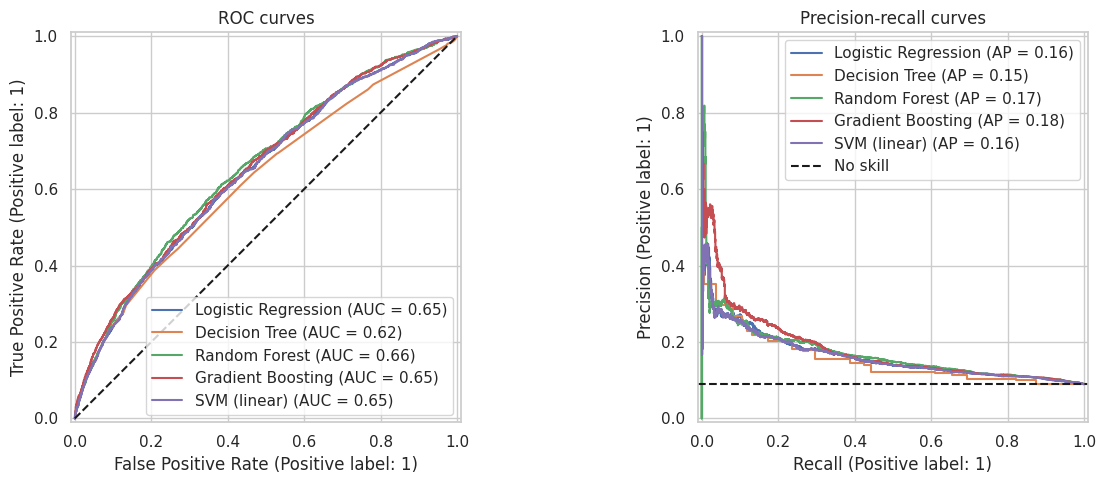

In [21]:
# ROC and precision-recall curves for all models
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, score in scores.items():
    RocCurveDisplay.from_predictions(y_test, score, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, score, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_title("ROC curves")
axes[1].axhline(y_test.mean(), color="k", ls="--", label="No skill")
axes[1].set_title("Precision-recall curves")
axes[1].legend()
plt.tight_layout()
plt.show()

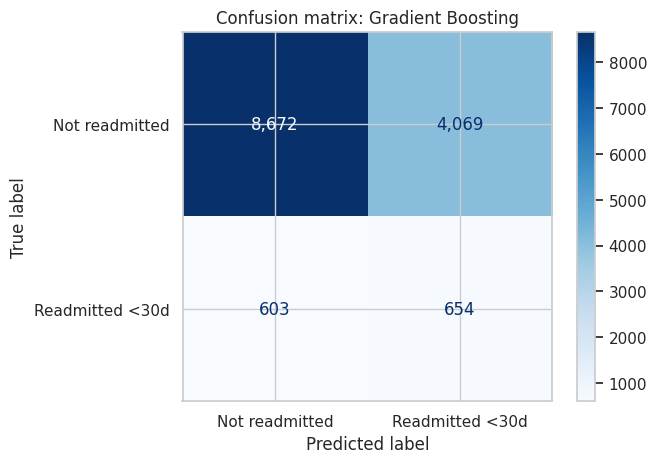

In [22]:
# Confusion matrix of the best model on the test set (default decision threshold)
ConfusionMatrixDisplay.from_predictions(y_test, fitted[best].predict(X_test),
                                        display_labels=["Not readmitted", "Readmitted <30d"],
                                        cmap="Blues", values_format=",")
plt.title(f"Confusion matrix: {best}")
plt.show()

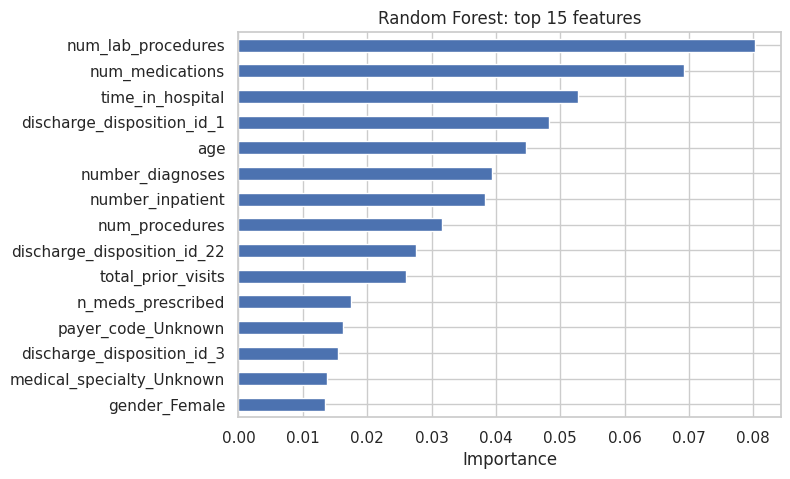

In [23]:
# Which features drive the Random Forest? (impurity-based importance on the test pipeline's encoded features)
rf = fitted["Random Forest"]
importance = pd.Series(rf[-1].feature_importances_, index=rf[0].get_feature_names_out())
importance.index = importance.index.str.replace(r"^(num|cat)__", "", regex=True)
importance.nlargest(15).sort_values().plot(kind="barh", figsize=(7, 5), title="Random Forest: top 15 features")
plt.xlabel("Importance")
plt.show()

In [24]:
# Auto-generated summary of the key numbers, so the interpretation below always matches the output
top_col = f"Recall@top{TOP_K:.0%}"
base = y_test.mean()
print(f"Best model by {PRIMARY_METRIC}: {best}")
print(f"  PR-AUC  {results.loc[best, 'PR-AUC']:.3f} vs no-skill {base:.3f} "
      f"({results.loc[best, 'PR-AUC'] / base:.1f}x the baseline)")
print(f"  ROC-AUC {results.loc[best, 'ROC-AUC']:.3f}")
print(f"  Flagging the top {TOP_K:.0%} of patients by risk catches {results.loc[best, top_col]:.1%} of readmissions "
      f"({results.loc[best, top_col] / TOP_K:.1f}x better than random)")
print(f"  At the default threshold: recall {results.loc[best, 'Recall']:.1%}, precision {results.loc[best, 'Precision']:.1%}, "
      f"accuracy {results.loc[best, 'Accuracy']:.1%}")
print("  Top Random Forest features:", ", ".join(importance.nlargest(5).index))
print("  Ranking by", PRIMARY_METRIC + ":", " > ".join(f"{m} ({v:.3f})" for m, v in results[PRIMARY_METRIC].items()))

Best model by PR-AUC: Gradient Boosting
  PR-AUC  0.180 vs no-skill 0.090 (2.0x the baseline)
  ROC-AUC 0.653
  Flagging the top 10% of patients by risk catches 23.9% of readmissions (2.4x better than random)
  At the default threshold: recall 52.0%, precision 13.8%, accuracy 66.6%
  Top Random Forest features: num_lab_procedures, num_medications, time_in_hospital, discharge_disposition_id_1, age
  Ranking by PR-AUC: Gradient Boosting (0.180) > Random Forest (0.171) > Logistic Regression (0.163) > SVM (linear) (0.162) > Decision Tree (0.154)


All five models perform similarly and only modestly better than chance. PR-AUC ranges from 0.154 (Decision Tree) to 0.180 (Gradient Boosting), which is 1.7 to 2.0 times the no-skill baseline of 0.090, and ROC-AUC ranges from 0.62 to 0.66. The simple Logistic Regression and linear SVM (PR-AUC 0.163 and 0.162) come close to the ensembles, which suggests the signal is weak and mostly additive rather than hidden in complex interactions. At the default threshold (with class weights) the models trade precision for recall differently: the Decision Tree finds 61% of readmissions at 12% precision, Gradient Boosting 52% at 14%, and Random Forest 32% at 18%. Accuracy (57% to 81%) is far below the 91% obtained by always predicting "not readmitted," confirming it is not a useful measure here. Operationally, the top 10% highest-risk patients from the best model contain 23.9% of all readmissions, 2.4 times better than random selection, but precision is 13.8%, so about 6 of every 7 flagged patients are not readmitted. In the Random Forest, `num_lab_procedures`, `num_medications`, `time_in_hospital`, discharge to home (`discharge_disposition_id_1`) and `age` rank highest. These impurity-based importances favor features with many distinct values, which is why `number_inpatient`, the largest effect in the inferential tests, ranks only seventh; both views agree that prior utilization, length of stay, age and illness burden matter and that no single feature dominates.

**Best model: Gradient Boosting.** It was selected because it has the highest PR-AUC (0.180), the metric fixed in advance in `PRIMARY_METRIC` for a rare outcome where accuracy is misleading. It also has the highest Recall@top 10% (23.9%), and its precision-recall curve appears to lie above the others at low recall, which is the region a care team with limited capacity would use. Random Forest has a slightly higher ROC-AUC (0.657 vs 0.653) and higher precision and F1 at the default threshold, but ranks second on the primary metric. The margin is small (0.009 PR-AUC over Random Forest) and comes from a single test split without confidence intervals, so the ranking among the top models should not be over-interpreted; the practical conclusion is that boosted trees give a modest edge over the Logistic Regression baseline (0.180 vs 0.163).

**Limitations and next steps.** Discrimination is modest (ROC-AUC about 0.65), consistent with readmission being hard to predict from administrative data alone, so a model like this could help prioritize follow-up but not replace clinical judgement. The models use default hyperparameters and a single train/test split, so tuning with cross-validation and bootstrapped confidence intervals is the main next step, along with choosing the decision threshold from follow-up capacity and checking calibration. Keeping each patient's first encounter ensures independent rows but discards later encounters and weakens the prior-visit features that were the strongest signals, and only readmissions to the same health system are observed. The data cover 1999-2008, so practice patterns and coding have changed, and performance should be audited by race, gender and age before any real use. Permutation importance or SHAP would give a more reliable explanation than the impurity-based importance shown above.

## 5. Pipeline Enhancements

1. **User upload with fallback logic**: `load_data()` lets the user upload a CSV from their computer, falls back to a local file, then to a UCI download, and checks the file type and readability. The pipeline should work for a user who has only the file, and also run unattended.
2. **Automated profiling and validation**: `profile()` reports size, duplicates, constant columns, and missing values; `validate()` checks required columns, binary target, unique IDs, and the minimum rows/predictors. Silent data problems (a renamed column, a bad target) would otherwise corrupt later results. The pipeline stops early with a specific message and confirms success when the data is acceptable.
3. **Data-driven cleaning in one function**: `clean()` drops columns above a missing-value threshold instead of hard-coding `weight`, removes died/hospice and repeat encounters, and logs how many rows each rule removed. The cleaning rules were previously only described in text, and a hard-coded column name would not adapt to new data. Cleaning is reproducible, transparent, and adapts to the dataset; one encounter per patient removes leakage between train and test.
4. **New feature engineering**: ICD-9 codes grouped into diagnosis categories; age bins converted to midpoints; added `total_prior_visits`, `n_meds_prescribed`, and `n_meds_changed`. Raw diagnosis codes have hundreds of levels, and the 23 medication columns are individually weak and sparse. Fewer, more informative predictors reduce overfitting and give the models stronger signals.
5. **Adaptive conditional logic**: Class weights are applied only when the positive class is below 30%; a linear SVM replaces the RBF-SVM above `SVM_MAX_ROWS` training rows. A fixed setup would be wrong for balanced data or impractically slow for large data.
6. **Model comparison summary and auto-generated results summary**: Added a sorted comparison table, ROC and precision-recall curves, a confusion matrix, Random Forest feature importance, and a code-generated summary of the key numbers. Single numbers hide behaviour across thresholds, and hand-typed numbers in text can drift from the output.